In [1]:
import pandas as pd
import numpy as np
import random
from Bio import SeqIO 

# A small constant to prevent log(0) errors
EPSILON = 1e-9

def calculate_cleavage_score(cleavage_preds, segments, core_len = 9):
    """
    Calculates a specialized cleavage score for a generic vaccine construct.

    Args:
        cleavage_preds: A NumPy array of cleavage probabilities for the full sequence.
        segments: A list of tuples, where each tuple is (segment_name, segment_length).
                  Example: [('Leader', 5), ('Linker1', 4), ('Epitope1', 15)]
        core_len: The length of the core binding motif to protect within 'Epitope' segments.

    Returns:
        The final composite cleavage score.
    """
    score_protection = 0.0
    score_processing = 0.0
    current_pos = 0

    for seg_name, seg_len in segments:
        if seg_len == 0:
            continue
        
        # Isolate the predictions for the current segment
        seg_preds = cleavage_preds[current_pos : current_pos + seg_len]
        #print(seg_preds)
        # Apply scoring logic based on segment name
        if 'epitope' in seg_name.lower():
            # --- Epitope Segment: Protect the core, reward flank cleavage ---
            core_offset = (seg_len - core_len) // 2
            core_start_local = core_offset
            core_end_local = core_start_local + core_len
            
            # Penalize cleavage within the core motif
            core_preds = seg_preds[core_start_local : core_end_local - 1]
            score_protection += np.log(1 - core_preds + EPSILON).sum()
            
            # Reward cleavage in the flanking regions
            flank_preds = np.concatenate([
                seg_preds[0 : core_start_local],
                seg_preds[core_end_local - 1 : seg_len]
            ])
            #print(flank_preds)
            if flank_preds.size > 0:
                score_processing += np.log(flank_preds.max() + EPSILON)
        else:
            # --- Other Segments (Linker, Leader, etc.): Reward cleavage ---
            if seg_preds.size > 0:
                score_processing += np.log(seg_preds.max() + EPSILON)
                #score_processing += np.log(seg_preds.sum() + EPSILON)

        # Move to the start of the next segment
        current_pos += seg_len
        
    return score_protection + score_processing


from Bio.SeqUtils.ProtParam import ProteinAnalysis

def analyze_vaccine_candidate(protein_sequence: str):
    """
    Calcula y devuelve las propiedades fisicoquímicas clave de una secuencia de proteína.

    Esta función utiliza Bio.SeqUtils.ProtParam de Biopython, que replica los cálculos
    de la herramienta ProtParam de ExPASy. Es ideal para el primer cribado de
    candidatos a vacunas multiepitópicas.

    Args:
        protein_sequence (str): La secuencia de aminoácidos de la vacuna candidata.

    Returns:
        dict: Un diccionario con las propiedades fisicoquímicas calculadas.
    """
    sequence = protein_sequence.strip().replace("\n", "")
    analysed_seq = ProteinAnalysis(sequence)

    molecular_weight = analysed_seq.molecular_weight()
    isoelectric_point = analysed_seq.isoelectric_point()
    instability_index = analysed_seq.instability_index()
    gravy = analysed_seq.gravy()

    return (molecular_weight,isoelectric_point,instability_index,gravy)

In [2]:
cleavage_df = pd.read_csv("../results/Q76R36_cleavage_results_5000_LE.csv")
fasta_constructs = SeqIO.to_dict(SeqIO.parse("../results/Q76R36_constructs_5000_LE.fasta", "fasta"))

In [3]:
cleavage_df["nid"] = cleavage_df.prot_id.str.split("|",expand=True)[0].str[9:].astype(int)

In [4]:
df_CD8 = cleavage_df.sort_values(by=["nid","position"])[:90054]

In [5]:
df_CD4 = cleavage_df.sort_values(by=["nid","position"])[90054:]

In [6]:
seq_scores_CD8 = []
for protid, protdf in df_CD8.groupby("prot_id"):
    segments= [('CALNNN',5),('Linker1', 4), ('Epitope1', 9)]

    pred = protdf.prediction
    vax_process_score = calculate_cleavage_score(pred, segments)
    seq_scores_CD8.append((protid,vax_process_score, protdf))
    
construct_scored_CD8 = sorted(seq_scores_CD8, key=lambda x: x[1],reverse=True)


In [90]:
construct_scored_CD8

[('construct2449|TWSM',
  -3.584158284033345,
                    prot_id  position      window  prediction   nid
  29070  construct2449|TWSM         1  XXXXXCALNN    0.146154  2449
  29071  construct2449|TWSM         2  XXXXCALNNT    0.058425  2449
  29072  construct2449|TWSM         3  XXXCALNNTW    0.438392  2449
  29073  construct2449|TWSM         4  XXCALNNTWS    0.006941  2449
  29074  construct2449|TWSM         5  XCALNNTWSM    0.009415  2449
  29075  construct2449|TWSM         6  CALNNTWSMD    0.006577  2449
  29076  construct2449|TWSM         7  ALNNTWSMDP    0.889762  2449
  29077  construct2449|TWSM         8  LNNTWSMDPL    0.003768  2449
  29078  construct2449|TWSM         9  NNTWSMDPLV    0.205788  2449
  29079  construct2449|TWSM        10  NTWSMDPLVV    0.013546  2449
  29080  construct2449|TWSM        11  TWSMDPLVVA    0.011571  2449
  29081  construct2449|TWSM        12  WSMDPLVVAA    0.118416  2449
  29082  construct2449|TWSM        13  SMDPLVVAAS    0.090170  2449
  

In [7]:
seq_scores_CD4 = []
for protid, protdf in df_CD4.groupby("prot_id"):
    segments= [('CALNNN',5),('Linker1', 4), ('Epitope1', 9)]

    pred = protdf.prediction
    vax_process_score = calculate_cleavage_score(pred, segments)
    seq_scores_CD4.append((protid,vax_process_score, protdf))
    
construct_scored_CD4 = sorted(seq_scores_CD4, key=lambda x: x[1],reverse=True)


In [41]:
# construct_scored = sorted(seq_scores, key=lambda x: x[1],reverse=True)
# top_construct = construct_scored[0]
# worst_construct = construct_scored[-1]

In [111]:
# top_construct,worst_score

## plot
Q76R36_E1_67,DPLVVAASI,I
Q76R36_E1_31,LVVAASIIG,II

In [8]:
from dna_features_viewer import GraphicFeature, GraphicRecord
import matplotlib.pyplot as plt

color_map = {'CALNN':'#ffcccc','linker1':'#ffcccc','linker2':'#ffcccc','epitopeCD8':'gold',
                 'epitopeCD4':'green','CPP':'#ccccff'}
def get_GraphicFeatures(d):
    
    record_features = list()
    s = 0
    e = 0
    for fname,fseq in d.items(): 
        e += len(fseq)

        gf = GraphicFeature(start=s, end=e, strand=0, color=color_map[fname],label=fname)
        record_features.append(gf)

        s = e
    return record_features

def plot_seqCleavage(dict_construct,cleavage_data, tag="PeptideCD8-CPP"):
    
    sequence = ''.join(dict_construct.values())
    
    features = get_GraphicFeatures(dict_construct)
    record = GraphicRecord(sequence=sequence, features=features)
    
    fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(14, 3), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
    )

    record.plot(ax=ax1,figure_width=12,figure_height=2,with_ruler=False)
    record.plot_sequence(ax1,guides_intensity=0.5)

    colormat=np.where(cleavage_data["prediction"]>=0.5,'r','black')
    ax2.bar(cleavage_data["position"] - 1,cleavage_data["prediction"],color=colormat,width=0.7)
    ax2.set_ylim(0,1)
    ax1.set_title(f"Cleavage predictions for {tag}")
    plt.savefig(f'{tag}.png', bbox_inches='tight')

## Prediccion de clivado para Top5 secuencias (score de procesamiento)

construct5650|THMW CALNNTHMWLVVAASIIG
Molecular Weight (Da):1913.27 pI: 6.73 Instability Index: 11.58 GRAVY: 1.211
construct9483|ETWW CALNNETWWLVVAASIIG
Molecular Weight (Da):1960.26 pI: 4.05 Instability Index: 7.95 GRAVY: 1.039
construct7452|TWSM CALNNTWSMLVVAASIIG
Molecular Weight (Da):1863.21 pI: 5.52 Instability Index: -3.62 GRAVY: 1.344
construct5837|EWTM CALNNEWTMLVVAASIIG
Molecular Weight (Da):1905.24 pI: 4.05 Instability Index: -7.26 GRAVY: 1.194
construct8961|EYRM CALNNEYRMLVVAASIIG
Molecular Weight (Da):1937.29 pI: 5.99 Instability Index: 0.05 GRAVY: 0.961


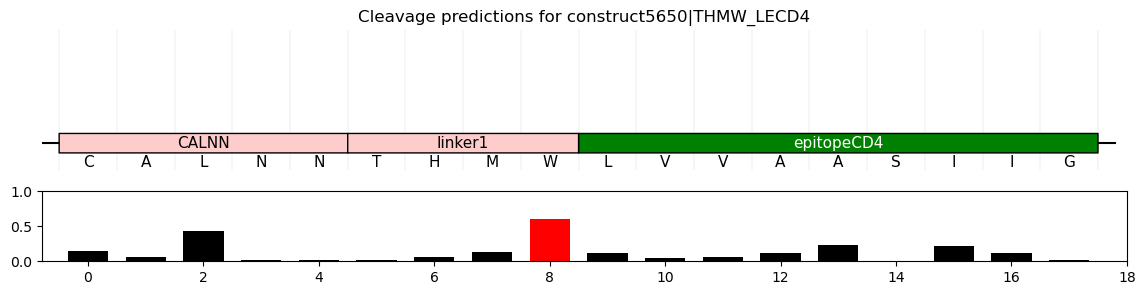

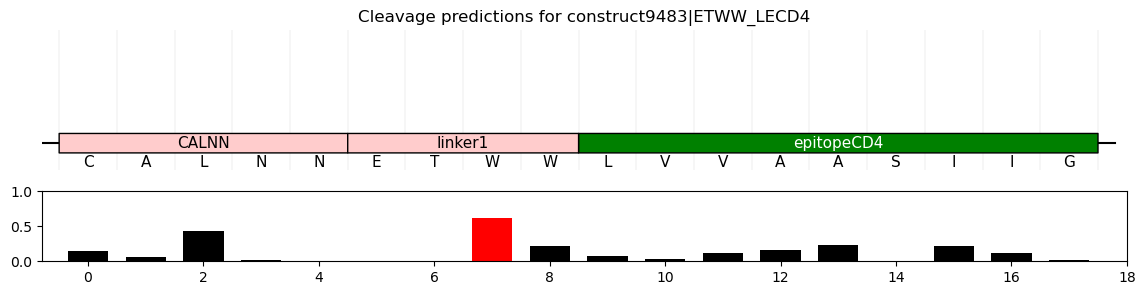

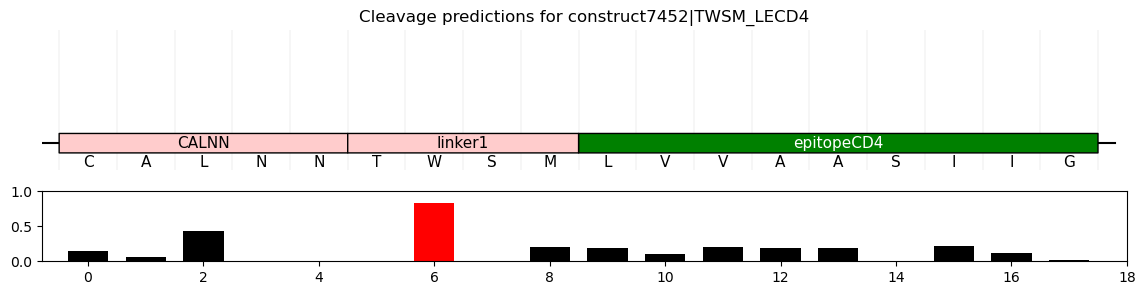

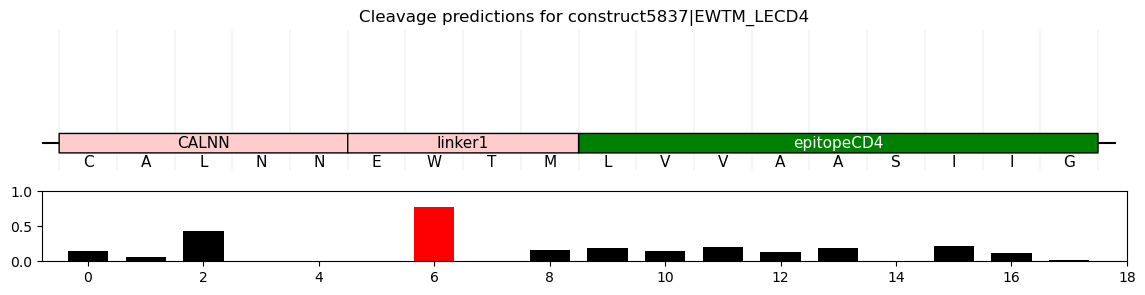

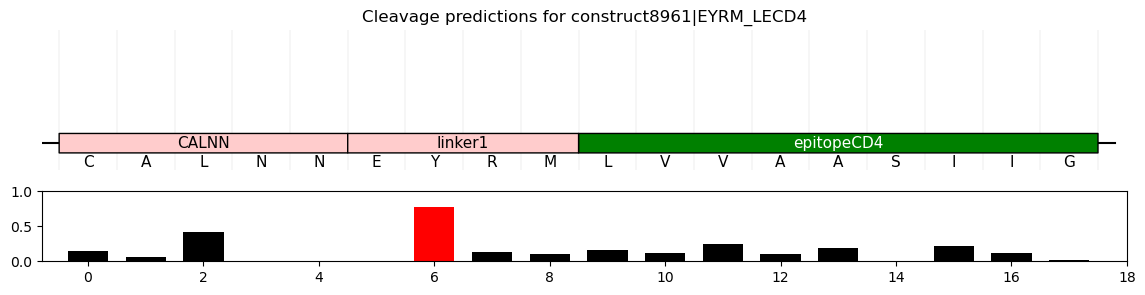

In [10]:

# plot top 5 - CD4
for data in construct_scored_CD4[:5]:
    seqname = data[0]
    seqscore = round(data[1],4)
    sequence = str(fasta_constructs[seqname].seq)
    
    constructELE = dict()
    constructELE["CALNN"] = sequence[:5]
    constructELE["linker1"] = sequence[5:5+4]
    if sequence[5+4:].startswith("LVVAASIIG"):
        constructELE["epitopeCD4"] = sequence[5+4:5+4+9]
    else:
        constructELE["epitopeCD8"] = sequence[5+4:5+4+9]
    

    properties = analyze_vaccine_candidate(sequence)
    if properties[2] < 40 and properties[3] <= 1.7:
        print(seqname, sequence)
        plot_seqCleavage(constructELE, data[2], tag=f"{seqname}_LECD4")
        print(f"Molecular Weight (Da):{properties[0]:.2f}",
        f"pI: {properties[1]:.2f}",
        f"Instability Index: {properties[2]:.2f}",
        f"GRAVY: {properties[3]:.3f}")

construct2449|TWSM CALNNTWSMDPLVVAASI
Molecular Weight (Da):1905.20 pI: 4.05 Instability Index: -3.62 GRAVY: 0.833
construct4802|TWHR CALNNTWHRDPLVVAASI
Molecular Weight (Da):1980.25 pI: 6.74 Instability Index: 9.53 GRAVY: 0.344
construct3092|NSYR CALNNNSYRDPLVVAASI
Molecular Weight (Da):1920.15 pI: 5.83 Instability Index: 0.05 GRAVY: 0.300
construct3448|TESW CALNNTESWDPLVVAASI
Molecular Weight (Da):1903.12 pI: 4.05 Instability Index: 26.13 GRAVY: 0.533
construct834|EWTM CALNNEWTMDPLVVAASI
Molecular Weight (Da):1947.24 pI: 4.05 Instability Index: -7.26 GRAVY: 0.683
construct107|SAYR CALNNSAYRDPLVVAASI
Molecular Weight (Da):1877.13 pI: 5.83 Instability Index: 0.05 GRAVY: 0.594
construct3958|EYRM CALNNEYRMDPLVVAASI
Molecular Weight (Da):1979.28 pI: 4.37 Instability Index: 0.05 GRAVY: 0.450
construct3374|HRYR CALNNHRYRDPLVVAASI
Molecular Weight (Da):2012.30 pI: 8.23 Instability Index: -4.14 GRAVY: 0.111
construct4276|TYRH CALNNTYRHDPLVVAASI
Molecular Weight (Da):1957.21 pI: 6.73 Instabili

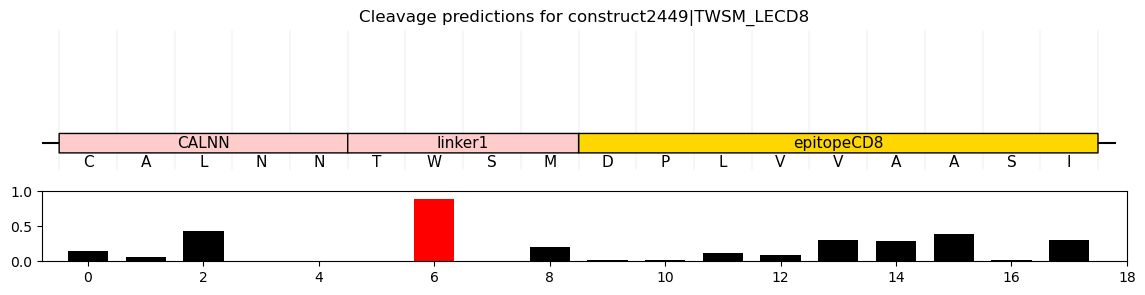

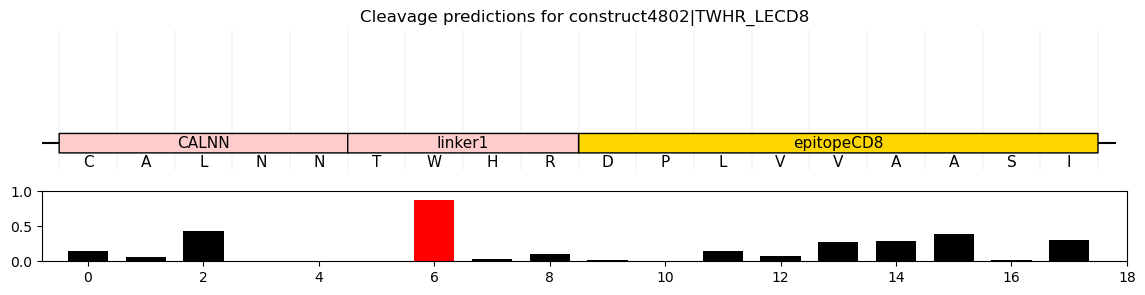

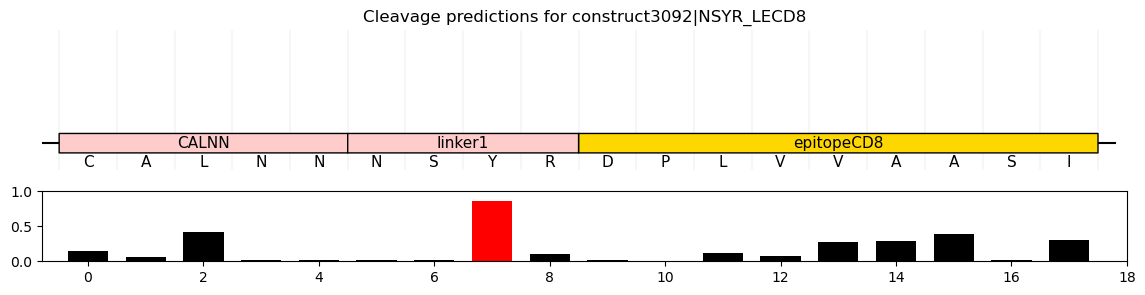

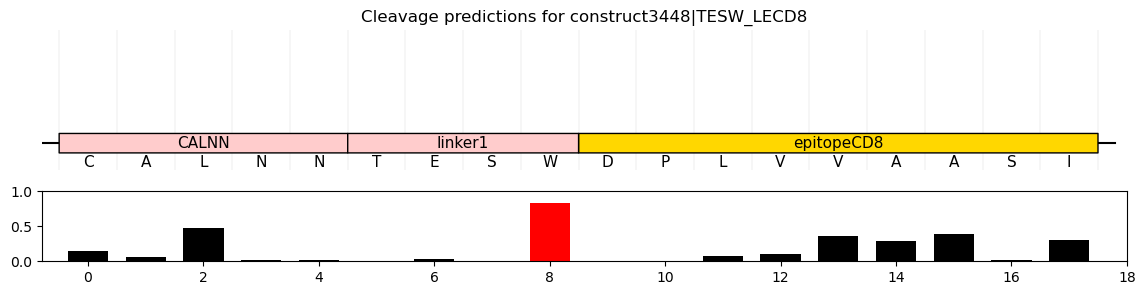

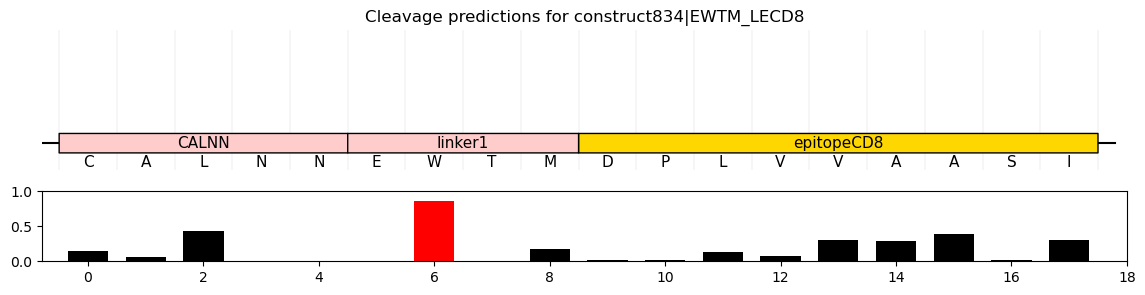

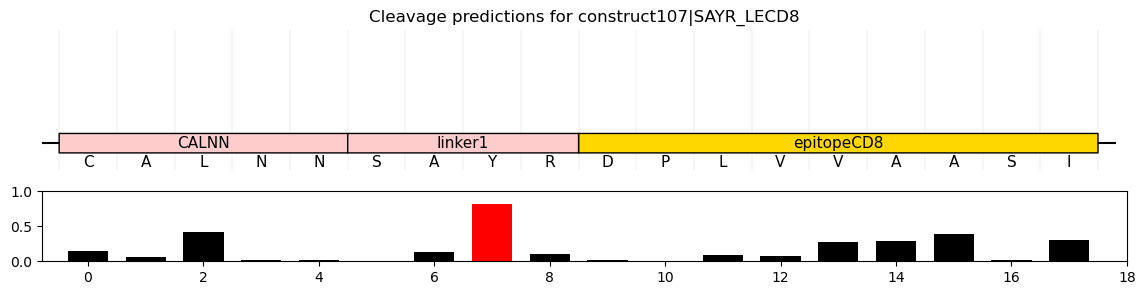

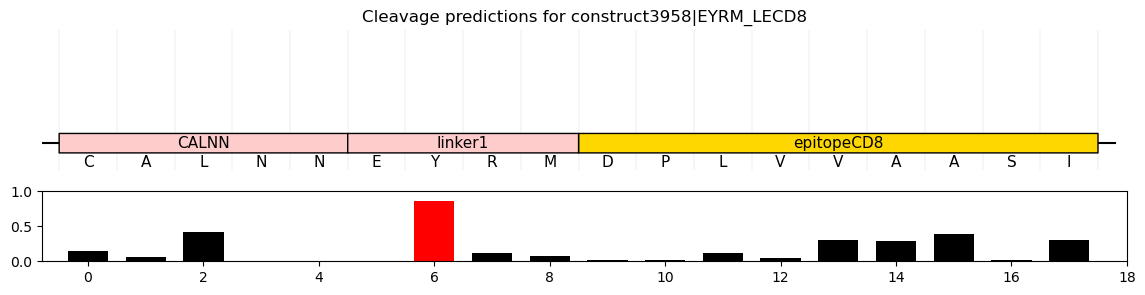

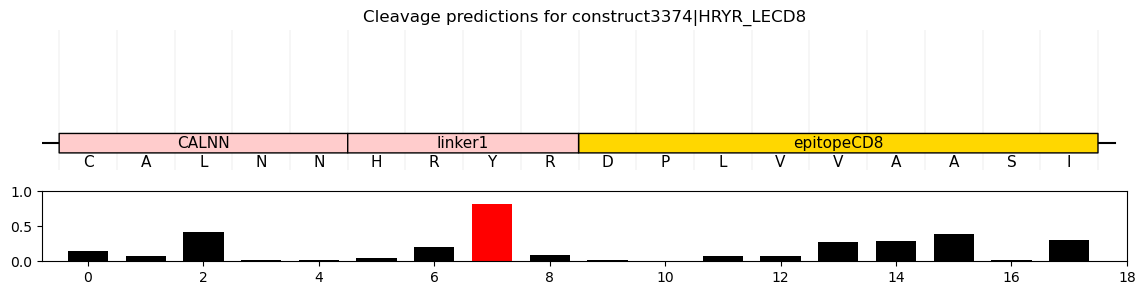

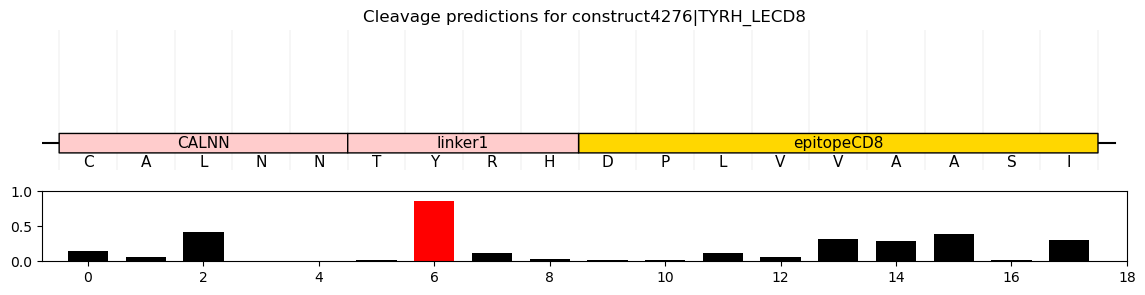

In [11]:
# plot top 5 - CD8
for data in construct_scored_CD8[:10]:
    seqname = data[0]
    seqscore = round(data[1],4)
    sequence = str(fasta_constructs[seqname].seq)
    
    constructELE = dict()
    constructELE["CALNN"] = sequence[:5]
    constructELE["linker1"] = sequence[5:5+4]
    if sequence[5+4:].startswith("LVVAASIIG"):
        constructELE["epitopeCD4"] = sequence[5+4:5+4+9]
    else:
        constructELE["epitopeCD8"] = sequence[5+4:5+4+9]

    properties = analyze_vaccine_candidate(sequence)
    if properties[2] < 40 and properties[3] <= 1.7:
        print(seqname, sequence)
        plot_seqCleavage(constructELE, data[2], tag=f"{seqname}_LECD8")
        print(f"Molecular Weight (Da):{properties[0]:.2f}",
        f"pI: {properties[1]:.2f}",
        f"Instability Index: {properties[2]:.2f}",
        f"GRAVY: {properties[3]:.3f}")

(array([  1.,   4.,   5.,   7.,  16.,  14.,  15.,  30.,  33.,  38.,  34.,
         31.,  46.,  38.,  51.,  51.,  68.,  90., 124., 141., 169., 202.,
        219., 247., 267., 285., 268., 293., 320., 344., 295., 305., 219.,
        188., 172., 155., 112.,  69.,  27.,  10.]),
 array([-11.30736912, -11.18361598, -11.05986285, -10.93610971,
        -10.81235657, -10.68860344, -10.5648503 , -10.44109717,
        -10.31734403, -10.1935909 , -10.06983776,  -9.94608462,
         -9.82233149,  -9.69857835,  -9.57482522,  -9.45107208,
         -9.32731894,  -9.20356581,  -9.07981267,  -8.95605954,
         -8.8323064 ,  -8.70855327,  -8.58480013,  -8.46104699,
         -8.33729386,  -8.21354072,  -8.08978759,  -7.96603445,
         -7.84228131,  -7.71852818,  -7.59477504,  -7.47102191,
         -7.34726877,  -7.22351564,  -7.0997625 ,  -6.97600936,
         -6.85225623,  -6.72850309,  -6.60474996,  -6.48099682,
         -6.35724368]),
 <BarContainer object of 40 artists>)

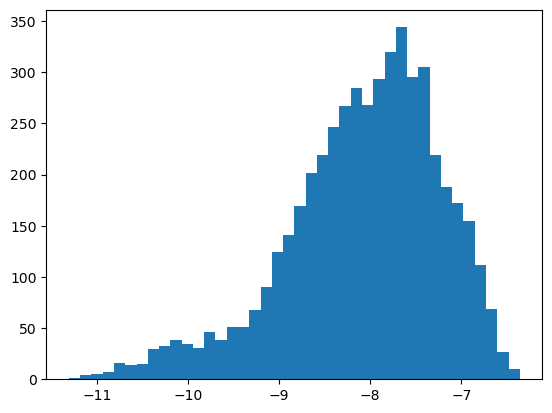

In [100]:
plt.hist([s[1] for s in construct_scored_CD4],bins=40)

## Prediccion de clivado para worst5 secuencias (score de procesamiento)

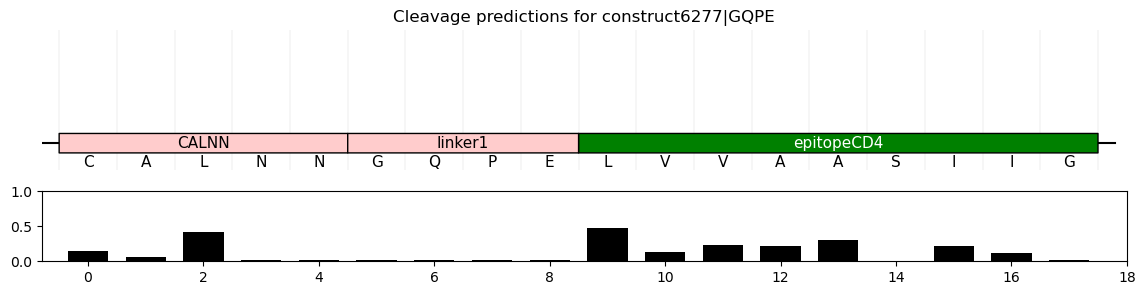

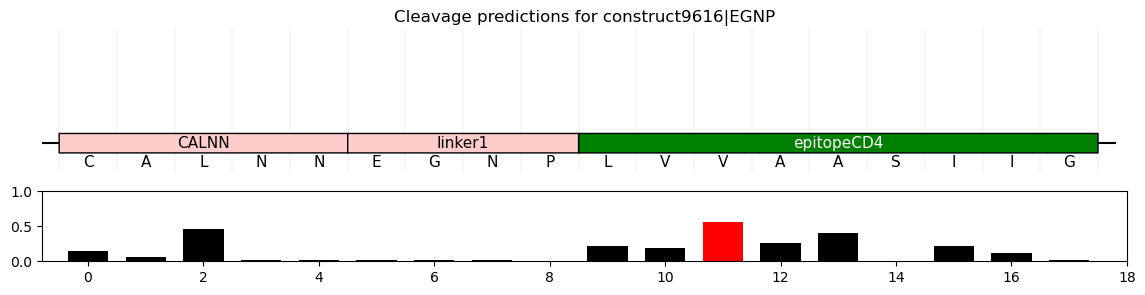

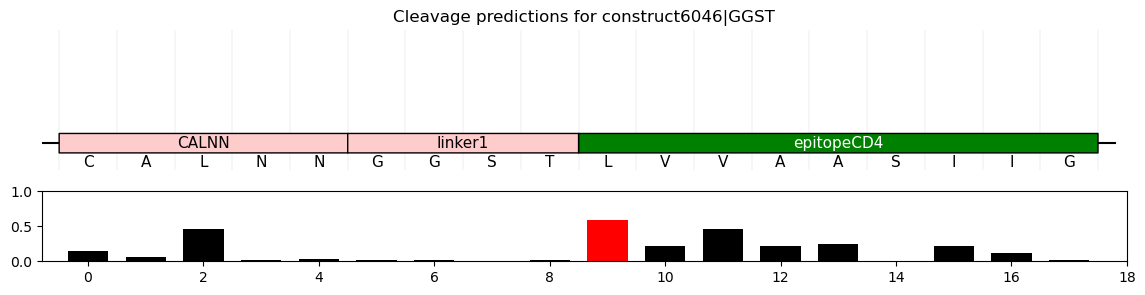

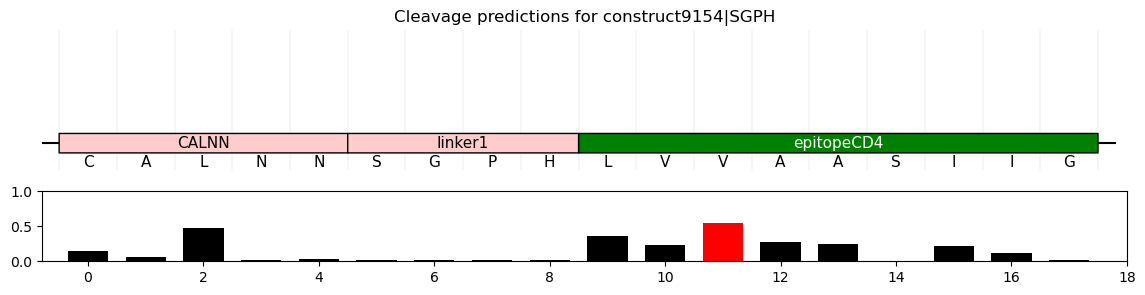

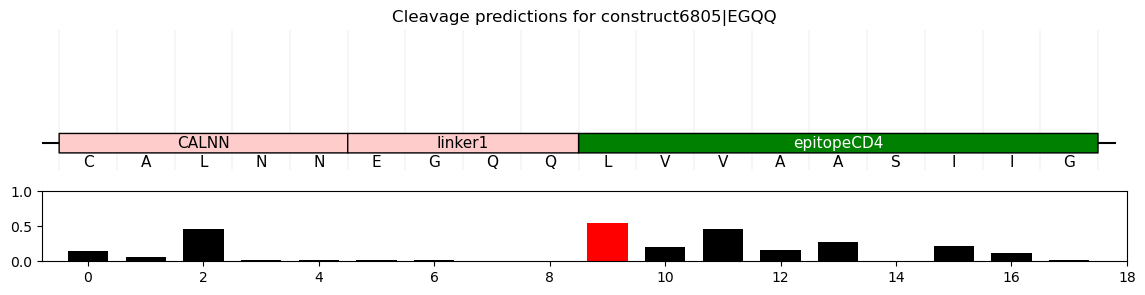

In [109]:
for data in construct_scored_CD4[-5:]:
    seqname = data[0]
    sequence = str(fasta_constructs[seqname].seq)
    
    constructELE = dict()
    constructELE["CALNN"] = sequence[:5]
    constructELE["linker1"] = sequence[5:5+4]
    if sequence[5+4:].startswith("LVVAASIIG"):
        constructELE["epitopeCD4"] = sequence[5+4:5+4+9]
    else:
        constructELE["epitopeCD8"] = sequence[5+4:5+4+9]
        
    plot_seqCleavage(constructELE, data[2], tag=f"{seqname}")

## Prediccion de clivado para Random5 secuencias (score de procesamiento)

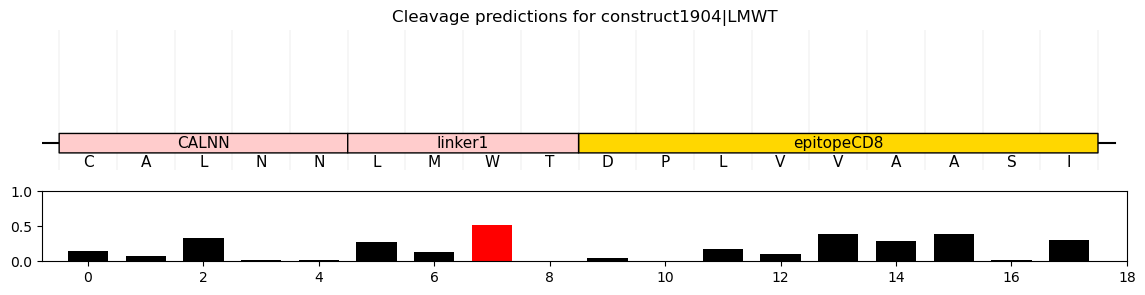

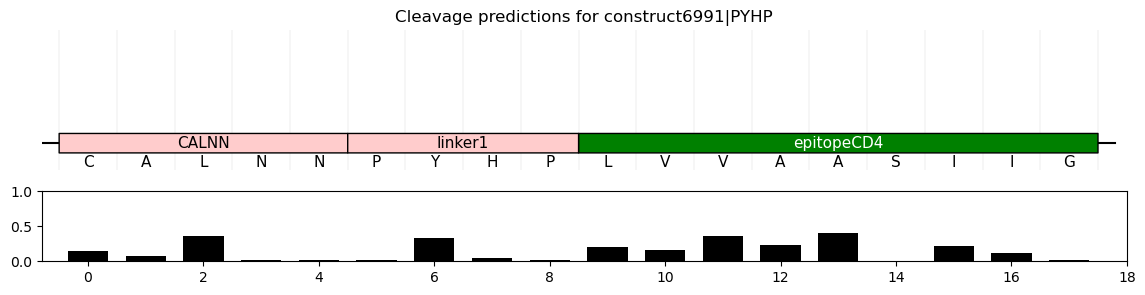

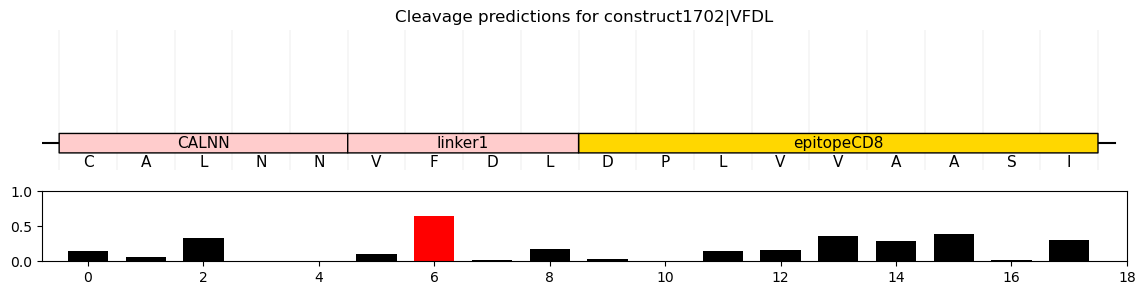

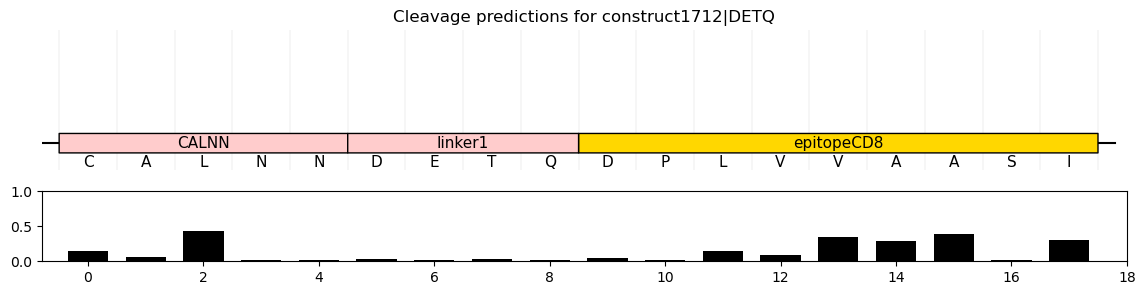

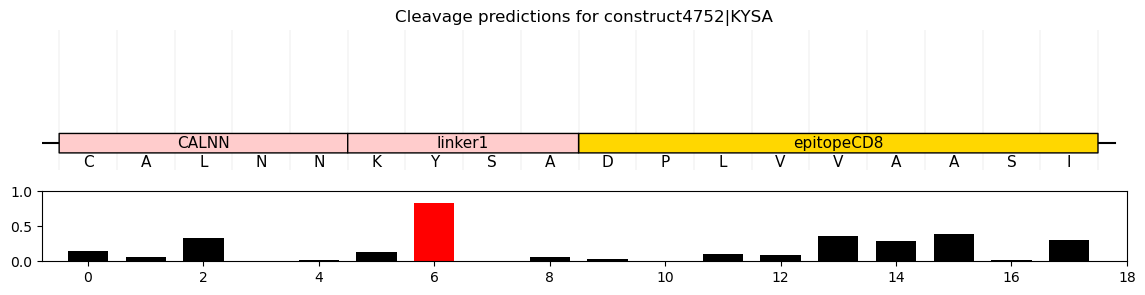

In [14]:
for data in random.choices(construct_scored[1000:],k=5):
    seqname = data[0]
    sequence = str(fasta_constructs[seqname].seq)
    
    constructELE = dict()
    constructELE["CALNN"] = sequence[:5]
    constructELE["linker1"] = sequence[5:5+4]
    if sequence[5+4:].startswith("LVVAASIIG"):
        constructELE["epitopeCD4"] = sequence[5+4:5+4+9]
    else:
        constructELE["epitopeCD8"] = sequence[5+4:5+4+9]
        
    plot_seqCleavage(constructELE, data[2], tag=f"{seqname}")

In [53]:
seq = str(fasta_constructs["construct7749|WVSS"].seq)
pred = next(filter(lambda s: s[0]=="construct7749|WVSS",construct_scored,))[2].prediction
seq

'LVVAASIIGWVSSDPLVVAASI'

In [52]:
pred

,prot_id,position,window,prediction
165066,construct7749|WVSS,1,XXXXXLVVAA,0.423641
165067,construct7749|WVSS,2,XXXXLVVAAS,0.221722
165068,construct7749|WVSS,3,XXXLVVAASI,0.363869
165069,construct7749|WVSS,4,XXLVVAASII,0.205982
165070,construct7749|WVSS,5,XLVVAASIIG,0.258905
165071,construct7749|WVSS,6,LVVAASIIGW,0.013127
165072,construct7749|WVSS,7,VVAASIIGWV,0.132007
165073,construct7749|WVSS,8,VAASIIGWVS,0.047270
165074,construct7749|WVSS,9,AASIIGWVSS,0.004742
165075,construct7749|WVSS,10,ASIIGWVSSD,0.720301


In [56]:
segments= [('Epitope1',9),('Linker1', 4), ('Epitope2', 9)]
calculate_cleavage_score(pred, segments)

165066    0.423641
165067    0.221722
165068    0.363869
165069    0.205982
165070    0.258905
165071    0.013127
165072    0.132007
165073    0.047270
165074    0.004742
Name: prediction, dtype: float64
[0.00474182]
165075    0.720301
165076    0.126342
165077    0.015306
165078    0.011987
Name: prediction, dtype: float64
165079    0.081190
165080    0.009360
165081    0.106939
165082    0.094334
165083    0.410026
165084    0.292405
165085    0.385951
165086    0.013492
165087    0.304091
Name: prediction, dtype: float64
[0.3040907]


-10.53847169658075

In [70]:
constructELE = dict()
constructELE["epitopeCD4"] = seq[:9]
constructELE["linker1"] = seq[9:9+4]
constructELE["epitopeCD8"] = seq[9+4:9+4+9]


In [72]:
top_construct[2]

,prot_id,position,window,prediction
118690,construct5851|RIAW,1,XXXXXLVVAA,0.423641
118691,construct5851|RIAW,2,XXXXLVVAAS,0.221722
118692,construct5851|RIAW,3,XXXLVVAASI,0.363869
118693,construct5851|RIAW,4,XXLVVAASII,0.205982
118694,construct5851|RIAW,5,XLVVAASIIG,0.258905
118695,construct5851|RIAW,6,LVVAASIIGR,0.010425
118696,construct5851|RIAW,7,VVAASIIGRI,0.199687
118697,construct5851|RIAW,8,VAASIIGRIA,0.076218
118698,construct5851|RIAW,9,AASIIGRIAW,0.027073
118699,construct5851|RIAW,10,ASIIGRIAWD,0.185414


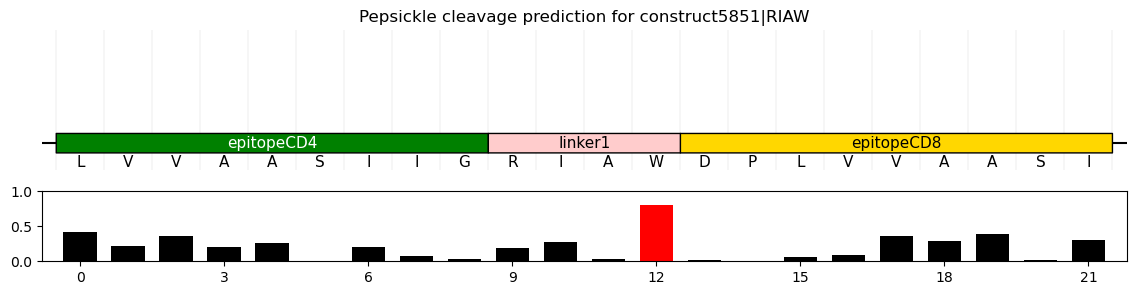

In [71]:
plot_seqCleavage(constructELE,top_construct[2],tag=f"{top_construct[0]}")

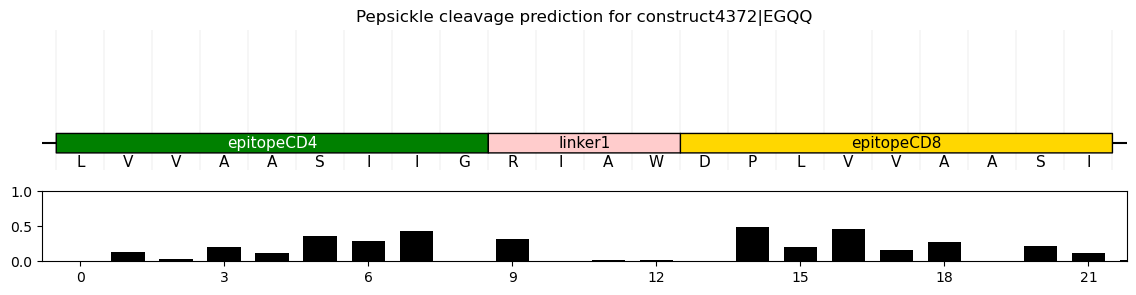

In [56]:
plot_seqCleavage(constructELE,worst_construct[2],tag=f"{worst_construct[0]}")